# EDA — Matriz de presencia de ASNs

Análisis exploratorio de cómo los ASNs aparecen y desaparecen día a día en la topología de Internet.
Fuente: matriz generada por `graph-analysis/asn-presence.py` a partir de los archivos `unique-asns-YYYYMMDD.txt`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from itertools import combinations

In [2]:
# --- Configuración ---

# PRESENCE_FILE = "../fetch/day-by-day/202504/asn-presence.txt"
PRESENCE_FILE = "../fetch/asn-presence-202504.txt"

# Sección 3: umbral de baja presencia
UMBRAL_BAJA_PRESENCIA = 0.30          # ASNs presentes menos del 30% de los días

# Sección 4: umbral para marcar días con churning anómalo
UMBRAL_CHURN_SIGMA = 2.0              # días con churn > media + N*σ

# Sección 5: clasificación de transiciones — mínimo de transiciones para "flapping"
MIN_TRANSICIONES_FLAP = 3

# Sección 7: twin detection — sólo ASNs con presencia por debajo de este umbral
TWIN_MAX_PRESENCIA = 0.90             # excluye ASNs presentes >= 90% de los días
TWIN_TOP_N = 30                       # pares más similares a mostrar

# Sección 8: análisis de flappers
NRO_STATS_FILE = "../fetch/nro-delegated-stats-20250430"

# Sección 9: estabilidad de peers entre episodios
TOPOLOGY_DIR = "../fetch/day-by-day/202504"

## 1. Carga y visión general

In [3]:
df = pd.read_csv(PRESENCE_FILE, sep=r"\s+", index_col=0)
df = df.astype(np.int8)  # el índice (ASN) queda como int64; sólo las columnas de datos se comprimen

# Convertir columnas a fechas para facilitar plots
df.columns = pd.to_datetime(df.columns, format="%Y%m%d")

n_asns, n_dias = df.shape
fecha_inicio = df.columns[0].date()
fecha_fin    = df.columns[-1].date()

# Detectar huecos en la secuencia de fechas
fechas_esperadas = pd.date_range(fecha_inicio, fecha_fin, freq="D")
huecos = fechas_esperadas.difference(df.columns)

print(f"ASNs únicos:      {n_asns:,}")
print(f"Días en matriz:   {n_dias}  ({fecha_inicio} → {fecha_fin})")
print(f"Días esperados:   {len(fechas_esperadas)}")
if len(huecos):
    print(f"Huecos detectados: {[str(d.date()) for d in huecos]}")
else:
    print("Sin huecos en la secuencia de fechas.")

ASNs únicos:      85,075
Días en matriz:   30  (2025-04-01 → 2025-04-30)
Días esperados:   30
Sin huecos en la secuencia de fechas.


## 2. Conteo diario de ASNs

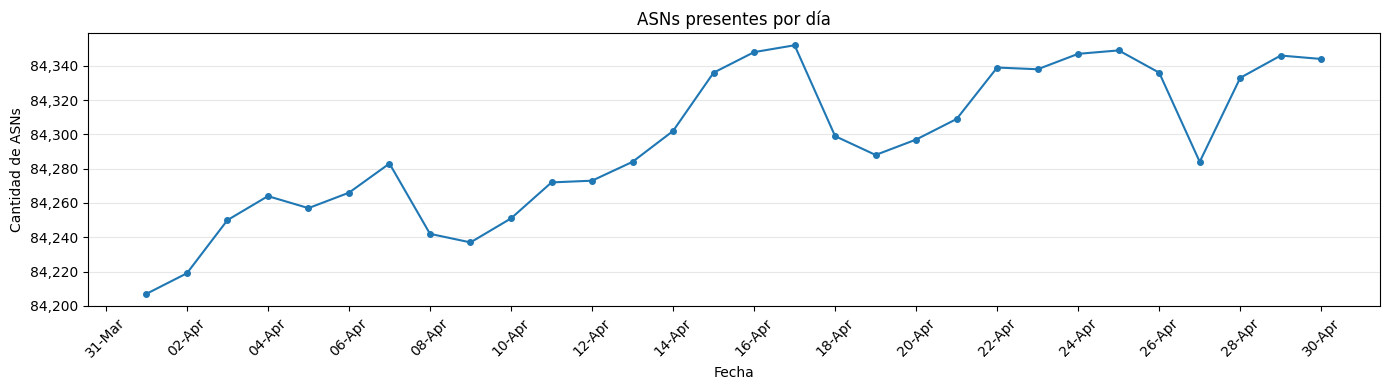

Mínimo: 84,207 (2025-04-01)
Máximo: 84,352 (2025-04-17)
Promedio: 84,295.1


In [4]:
conteo_diario = df.sum(axis=0)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(conteo_diario.index, conteo_diario.values, marker="o", markersize=4, linewidth=1.5)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.xticks(rotation=45)
ax.set_title("ASNs presentes por día")
ax.set_ylabel("Cantidad de ASNs")
ax.set_xlabel("Fecha")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Mínimo: {conteo_diario.min():,} ({conteo_diario.idxmin().date()})")
print(f"Máximo: {conteo_diario.max():,} ({conteo_diario.idxmax().date()})")
print(f"Promedio: {conteo_diario.mean():,.1f}")

## 3. Distribución de tasa de presencia

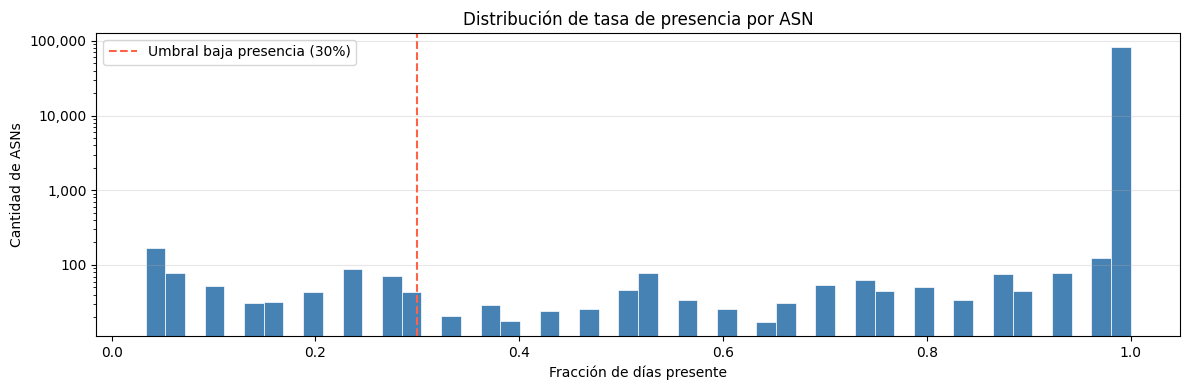

In [5]:
tasa_presencia = df.mean(axis=1)  # fracción de días en que cada ASN está presente

fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(tasa_presencia, bins=50, color="steelblue", edgecolor="white", linewidth=0.5)
ax.axvline(UMBRAL_BAJA_PRESENCIA, color="tomato", linestyle="--", label=f"Umbral baja presencia ({UMBRAL_BAJA_PRESENCIA:.0%})")
ax.set_title("Distribución de tasa de presencia por ASN")
ax.set_xlabel("Fracción de días presente")
ax.set_ylabel("Cantidad de ASNs")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

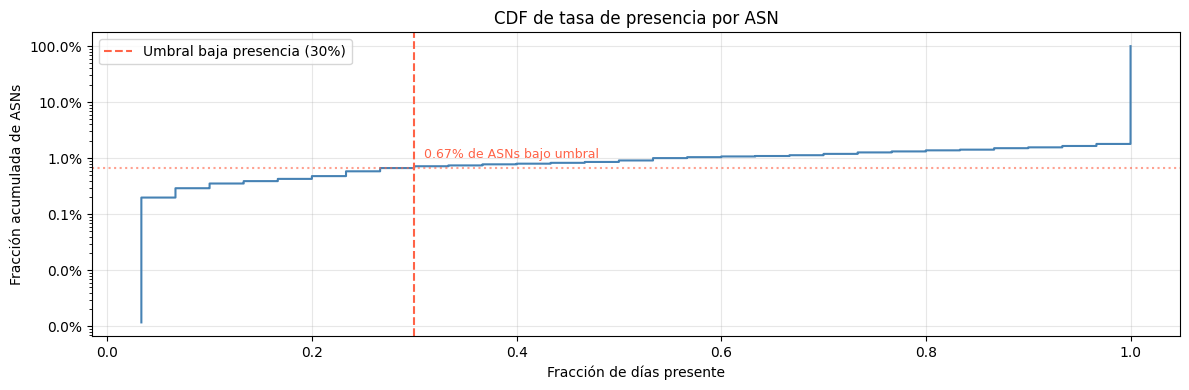

In [6]:
sorted_tasa = np.sort(tasa_presencia.values)
n = len(sorted_tasa)
ecdf_y = np.arange(1, n + 1) / n

frac_below = (tasa_presencia < UMBRAL_BAJA_PRESENCIA).mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(sorted_tasa, ecdf_y, color="steelblue", linewidth=1.5, drawstyle="steps-post")
ax.axvline(UMBRAL_BAJA_PRESENCIA, color="tomato", linestyle="--",
           label=f"Umbral baja presencia ({UMBRAL_BAJA_PRESENCIA:.0%})")
ax.axhline(frac_below, color="tomato", linestyle=":", alpha=0.6)
ax.annotate(f"{frac_below:.2%} de ASNs bajo umbral",
            xy=(UMBRAL_BAJA_PRESENCIA + 0.01, frac_below * 1.5),
            fontsize=9, color="tomato")
ax.set_yscale("log")
#ax.set_xscale("log")
ax.set_title("CDF de tasa de presencia por ASN")
ax.set_xlabel("Fracción de días presente")
ax.set_ylabel("Fracción acumulada de ASNs")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# ASNs con baja presencia
baja_presencia = tasa_presencia[tasa_presencia < UMBRAL_BAJA_PRESENCIA].sort_values()
print(f"ASNs con presencia < {UMBRAL_BAJA_PRESENCIA:.0%}: {len(baja_presencia):,}")

df_baja = pd.DataFrame({
    "ASN": baja_presencia.index,
    "días_presente": (baja_presencia * n_dias).astype(int).values,
    "tasa_presencia": baja_presencia.values,
})
df_baja.head(20)

ASNs con presencia < 30%: 568


,ASN,días_presente,tasa_presencia
0,11,1,0.033333
1,142078,1,0.033333
2,142079,1,0.033333
3,142080,1,0.033333
4,142081,1,0.033333
5,142082,1,0.033333
6,142083,1,0.033333
7,142084,1,0.033333
8,142085,1,0.033333
9,142086,1,0.033333


## 4. Churn diario (apariciones y desapariciones)

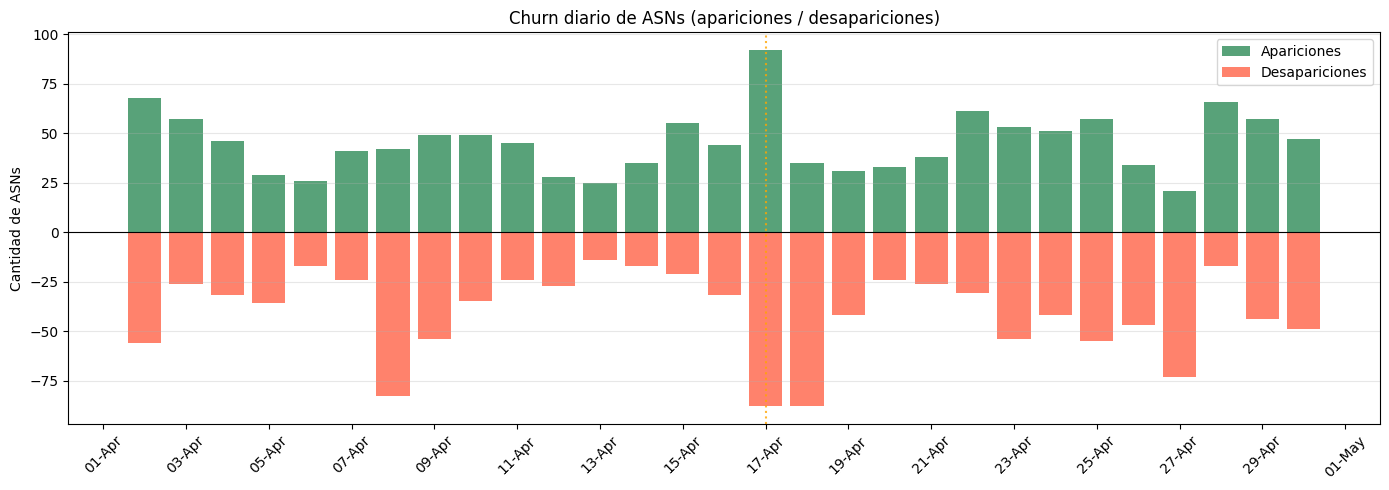

Días con churn anómalo (> media + 2.0σ = 145):
  2025-04-17  churn=180  (+92 / -88)


In [8]:
# Diferencia día a día: +1 = apareció, -1 = desapareció
diff = df.diff(axis=1).iloc[:, 1:]  # primera columna es NaN tras diff

apariciones   = (diff ==  1).sum(axis=0)
desapariciones = (diff == -1).sum(axis=0)
churn_total   = apariciones + desapariciones

media_churn = churn_total.mean()
sigma_churn = churn_total.std()
umbral_anomalia = media_churn + UMBRAL_CHURN_SIGMA * sigma_churn

dias_anomalos = churn_total[churn_total > umbral_anomalia]

fig, ax = plt.subplots(figsize=(14, 5))
fechas = apariciones.index
ax.bar(fechas, apariciones.values,  label="Apariciones",    color="seagreen",  alpha=0.8)
ax.bar(fechas, -desapariciones.values, label="Desapariciones", color="tomato", alpha=0.8)
ax.axhline(0, color="black", linewidth=0.8)
for fecha in dias_anomalos.index:
    ax.axvline(fecha, color="orange", linestyle=":", linewidth=1.5, alpha=0.8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.xticks(rotation=45)
ax.set_title("Churn diario de ASNs (apariciones / desapariciones)")
ax.set_ylabel("Cantidad de ASNs")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

if len(dias_anomalos):
    print(f"Días con churn anómalo (> media + {UMBRAL_CHURN_SIGMA}σ = {umbral_anomalia:.0f}):")
    for fecha, val in dias_anomalos.items():
        print(f"  {fecha.date()}  churn={val:,}  (+{apariciones[fecha]:,} / -{desapariciones[fecha]:,})")
else:
    print("No se detectaron días con churn anómalo.")

## 5. Clasificación de ASNs por patrón de transiciones

Cada ASN se clasifica en una de las siguientes categorías según su secuencia de presencia a lo largo del período:

| Clase | Descripción |
|-------|-------------|
| **estable_presente** | Presente todos los días del período. No tiene ninguna transición. |
| **estable_ausente** | Ausente todos los días. Aparece en la matriz porque estaba presente en algún otro período analizado junto a éste. |
| **naciendo** | Ausente al comienzo y presente al final: una única transición 0→1 sin retorno. Puede indicar un AS recién asignado o que acaba de comenzar a anunciarse. |
| **muriendo** | Presente al comienzo y ausente al final: una única transición 1→0 sin retorno. Puede indicar un AS que dejó de anunciarse o fue retirado. |
| **renaciendo** | Tuvo al menos una desaparición y una reaparición, y su última transición fue 0→1. Volvió a estar presente al final del período. |
| **flapping** | Tiene `MIN_TRANSICIONES_FLAP` o más transiciones en total. Señal de inestabilidad: el AS aparece y desaparece repetidamente. |
| **esporádico** | Tiene transiciones pero no encaja en ninguno de los patrones anteriores. Presencia irregular sin una tendencia clara. |

In [9]:
def clasificar(fila):
    """Clasifica un ASN según su patrón de presencia."""
    vals = fila.values
    transiciones = np.diff(vals.astype(np.int8))
    n_01 = (transiciones ==  1).sum()  # 0 → 1: aparición
    n_10 = (transiciones == -1).sum()  # 1 → 0: desaparición
    total = n_01 + n_10

    if total == 0:
        return "estable_presente" if vals[0] == 1 else "estable_ausente"
    if total >= MIN_TRANSICIONES_FLAP:
        return "flapping"
    if n_01 == 1 and n_10 == 0 and vals[0] == 0:
        return "naciendo"
    if n_10 == 1 and n_01 == 0 and vals[-1] == 0:
        return "muriendo"
    if n_01 >= 1 and n_10 >= 1:
        ultima = np.where(transiciones != 0)[0][-1]
        return "renaciendo" if transiciones[ultima] == 1 else "esporádico"
    return "esporádico"

clases = df.apply(clasificar, axis=1)
conteo_clases = clases.value_counts()
print(conteo_clases.to_string())

estable_presente    83545
naciendo              574
muriendo              464
flapping              175
esporádico            174
renaciendo            143


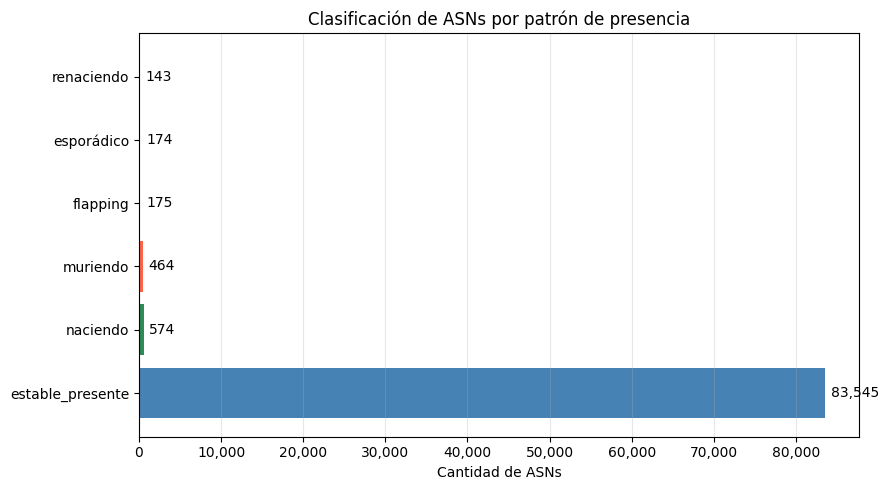

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
colores = {
    "estable_presente": "steelblue",
    "estable_ausente":  "lightsteelblue",
    "naciendo":         "seagreen",
    "muriendo":         "tomato",
    "renaciendo":       "gold",
    "flapping":         "darkorange",
    "esporádico":       "plum",
}
bars = ax.barh(
    conteo_clases.index,
    conteo_clases.values,
    color=[colores.get(c, "gray") for c in conteo_clases.index]
)
ax.bar_label(bars, fmt=lambda x: f"{int(x):,}", padding=4)
ax.set_title("Clasificación de ASNs por patrón de presencia")
ax.set_xlabel("Cantidad de ASNs")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Tablas por categoría de interés
for categoria in ["naciendo", "muriendo", "renaciendo", "flapping"]:
    asns = clases[clases == categoria].index
    if len(asns) == 0:
        continue
    print(f"\n── {categoria.upper()} ({len(asns):,} ASNs) ──")
    sub = df.loc[asns].copy()
    sub["tasa"] = tasa_presencia.loc[asns]
    sub["transiciones"] = sub.drop(columns="tasa").apply(
        lambda r: int(np.diff(r.values.astype(np.int8).__abs__()).sum()), axis=1
    )
    display(sub[["tasa", "transiciones"]].sort_values("transiciones", ascending=False).head(15))


── NACIENDO (574 ASNs) ──


,tasa,transiciones
ASN,,
914,0.533333,1
213455,0.266667,1
213196,0.100000,1
213333,0.266667,1
213377,0.700000,1
213385,0.966667,1
213441,0.433333,1
213442,0.100000,1
213461,0.700000,1



── MURIENDO (464 ASNs) ──


,tasa,transiciones
ASN,,
403,0.366667,-1
206126,0.266667,-1
209070,0.866667,-1
209051,0.300000,-1
207854,0.866667,-1
207782,0.933333,-1
207566,0.600000,-1
207532,0.733333,-1
207396,0.233333,-1



── RENACIENDO (143 ASNs) ──


,tasa,transiciones
ASN,,
5433,0.966667,0
262520,0.966667,0
215343,0.900000,0
215624,0.666667,0
215643,0.866667,0
215819,0.733333,0
216394,0.966667,0
216402,0.866667,0
263692,0.933333,0



── FLAPPING (175 ASNs) ──


,tasa,transiciones
ASN,,
408,0.700000,1
210969,0.433333,1
210499,0.300000,1
209935,0.133333,1
206380,0.300000,1
153722,0.933333,1
153656,0.566667,1
152681,0.433333,1
150783,0.333333,1


## 6. Sesgo por día de la semana

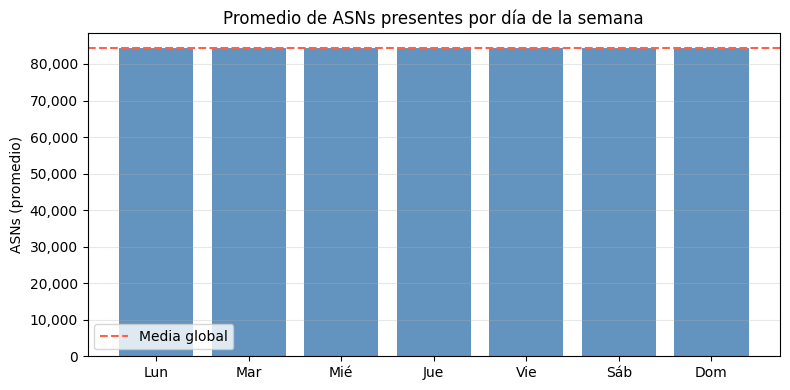

Rango inter-día: 24 ASNs  (0.03% de la media)


In [12]:
nombres_dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
conteo_por_dow = conteo_diario.copy()
conteo_por_dow.index = conteo_por_dow.index.dayofweek
media_por_dow = conteo_por_dow.groupby(level=0).mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([nombres_dias[i] for i in media_por_dow.index], media_por_dow.values, color="steelblue", alpha=0.85)
ax.axhline(conteo_diario.mean(), color="tomato", linestyle="--", label="Media global")
ax.set_title("Promedio de ASNs presentes por día de la semana")
ax.set_ylabel("ASNs (promedio)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

rango = media_por_dow.max() - media_por_dow.min()
print(f"Rango inter-día: {rango:,.0f} ASNs  ({rango / conteo_diario.mean():.2%} de la media)")

## 7. Detección de twins (ASNs correlacionados)

In [13]:
# Restringir a ASNs variables (presencia < TWIN_MAX_PRESENCIA)
variables = tasa_presencia[tasa_presencia < TWIN_MAX_PRESENCIA].index
print(f"ASNs variables (presencia < {TWIN_MAX_PRESENCIA:.0%}): {len(variables):,}")

mat = df.loc[variables].values.astype(np.float32)  # shape: (n_variables, n_dias)

# Similitud de Jaccard vectorizada: |A∩B| / |A∪B|
# Para vectores binarios: intersección = dot product, unión = sum(a) + sum(b) - dot
interseccion = mat @ mat.T
presencias   = mat.sum(axis=1, keepdims=True)
union        = presencias + presencias.T - interseccion
# Evitar división por cero (ASNs nunca presentes ya están filtrados, pero por seguridad)
with np.errstate(invalid="ignore", divide="ignore"):
    jaccard = np.where(union > 0, interseccion / union, 0.0)
np.fill_diagonal(jaccard, 0)  # ignorar auto-similitud

print(f"Matriz de similitud calculada: {jaccard.shape}")

ASNs variables (presencia < 90%): 1,285
Matriz de similitud calculada: (1285, 1285)


In [14]:
# Extraer top-N pares
# Tomar sólo el triángulo superior para no duplicar pares
i_idx, j_idx = np.triu_indices(len(variables), k=1)
sims = jaccard[i_idx, j_idx]
top_idx = np.argsort(sims)[-TWIN_TOP_N:][::-1]

asns_arr = variables.to_numpy()
pares = [
    (asns_arr[i_idx[k]], asns_arr[j_idx[k]], sims[k])
    for k in top_idx
]

df_twins = pd.DataFrame(pares, columns=["ASN_A", "ASN_B", "jaccard"])
print(f"Top {TWIN_TOP_N} pares más similares:")
display(df_twins)

Top 30 pares más similares:


,ASN_A,ASN_B,jaccard
0,1096,152378,1.0
1,142085,142098,1.0
2,133589,273906,1.0
3,142085,142106,1.0
4,142085,142105,1.0
5,142085,142104,1.0
6,142085,142103,1.0
7,142085,142102,1.0
8,142085,142101,1.0
9,142085,142100,1.0


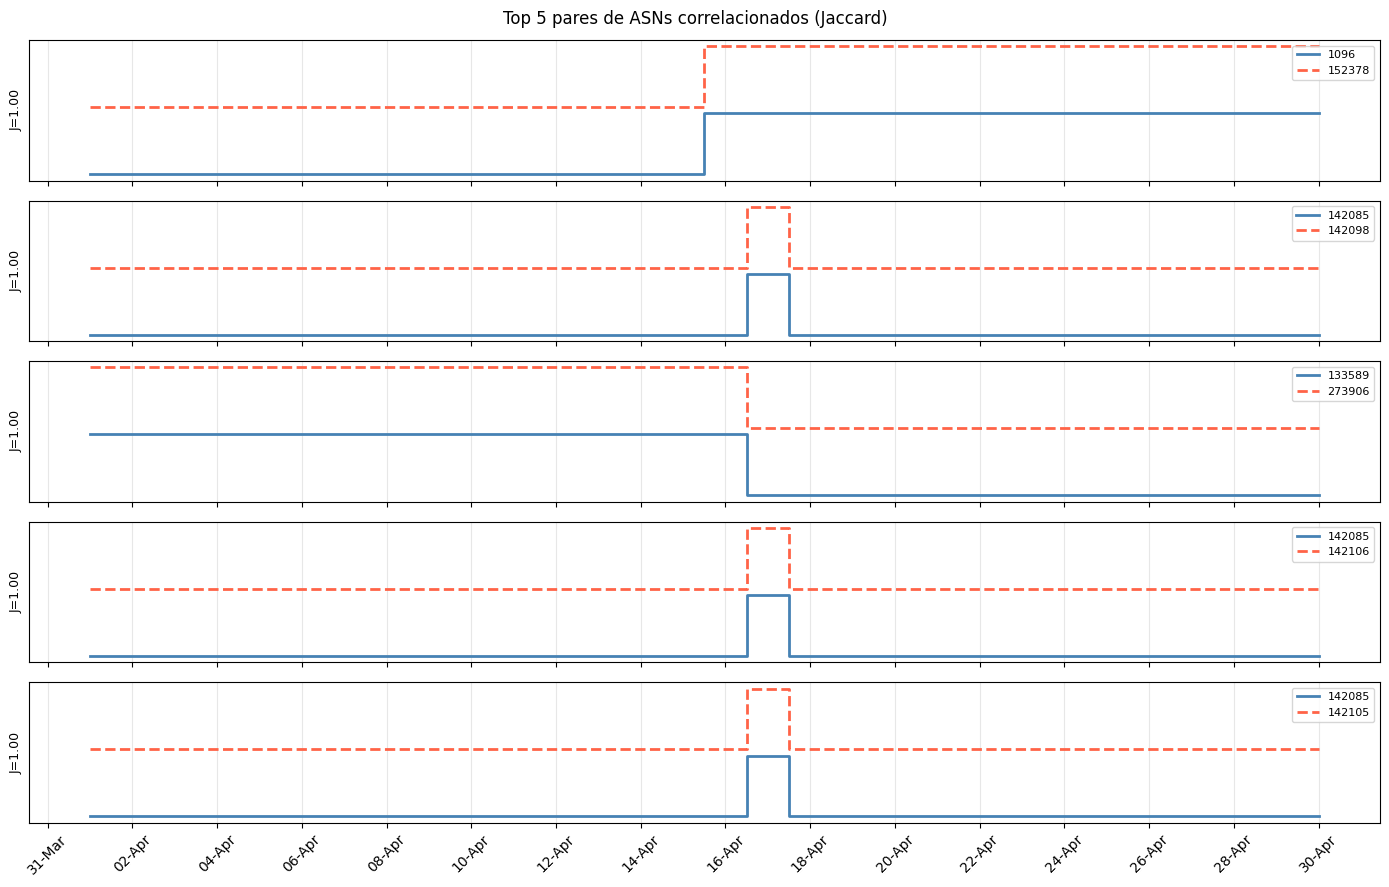

In [15]:
# Visualizar los top-5 pares lado a lado
TOP_PLOT = 5
fig, axes = plt.subplots(TOP_PLOT, 1, figsize=(14, TOP_PLOT * 1.8), sharex=True)

for ax, (asn_a, asn_b, sim) in zip(axes, pares[:TOP_PLOT]):
    fechas = df.columns
    va = df.loc[asn_a].values
    vb = df.loc[asn_b].values
    ax.step(fechas, va,       where="mid", label=f"{asn_a}", linewidth=2, color="steelblue")
    ax.step(fechas, vb + 1.1, where="mid", label=f"{asn_b}", linewidth=2, color="tomato", linestyle="--")
    ax.set_yticks([])
    ax.set_ylabel(f"J={sim:.2f}", fontsize=9)
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(axis="x", alpha=0.3)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
axes[-1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.xticks(rotation=45)
fig.suptitle(f"Top {TOP_PLOT} pares de ASNs correlacionados (Jaccard)", fontsize=12)
plt.tight_layout()
plt.show()

## 8. Análisis de ASNs flapping

Enriquecemos los 102 ASNs clasificados como *flapping* con datos del RIR y país de origen (NRO delegated stats) y buscamos patrones temporales, de transiciones y geográficos.

In [16]:
# Cargar NRO delegated stats → dicts ASN → rir / cc
asn_to_rir: dict[int, str] = {}
asn_to_cc:  dict[int, str] = {}

with open(NRO_STATS_FILE) as fh:
    for line in fh:
        parts = line.strip().split("|")
        if len(parts) < 7:
            continue
        if parts[1] == "*" or parts[2] != "asn" or parts[6] != "assigned":
            continue
        try:
            start = int(parts[3])
            count = int(parts[4])
        except ValueError:
            continue
        rir = parts[0]
        cc  = parts[1].lower()
        for asn in range(start, start + count):
            asn_to_rir[asn] = rir
            asn_to_cc[asn]  = cc

print(f"NRO stats: {len(asn_to_rir):,} ASNs registrados")

# Construir tabla enriquecida de flappers
flap_asns = clases[clases == "flapping"].index

df_flapping = pd.DataFrame({
    "transiciones": [int(np.abs(np.diff(df.loc[a].values.astype(np.int8))).sum()) for a in flap_asns],
    "tasa":         tasa_presencia.loc[flap_asns].values,
    "rir":          [asn_to_rir.get(int(a), "desconocido") for a in flap_asns],
    "cc":           [asn_to_cc.get(int(a),  "??")          for a in flap_asns],
}, index=flap_asns)
df_flapping.index.name = "ASN"

print(f"\nFlappers por RIR:")
print(df_flapping["rir"].value_counts().to_string())

NRO stats: 118,521 ASNs registrados

Flappers por RIR:
rir
arin           58
ripencc        52
apnic          36
lacnic         17
afrinic        11
desconocido     1


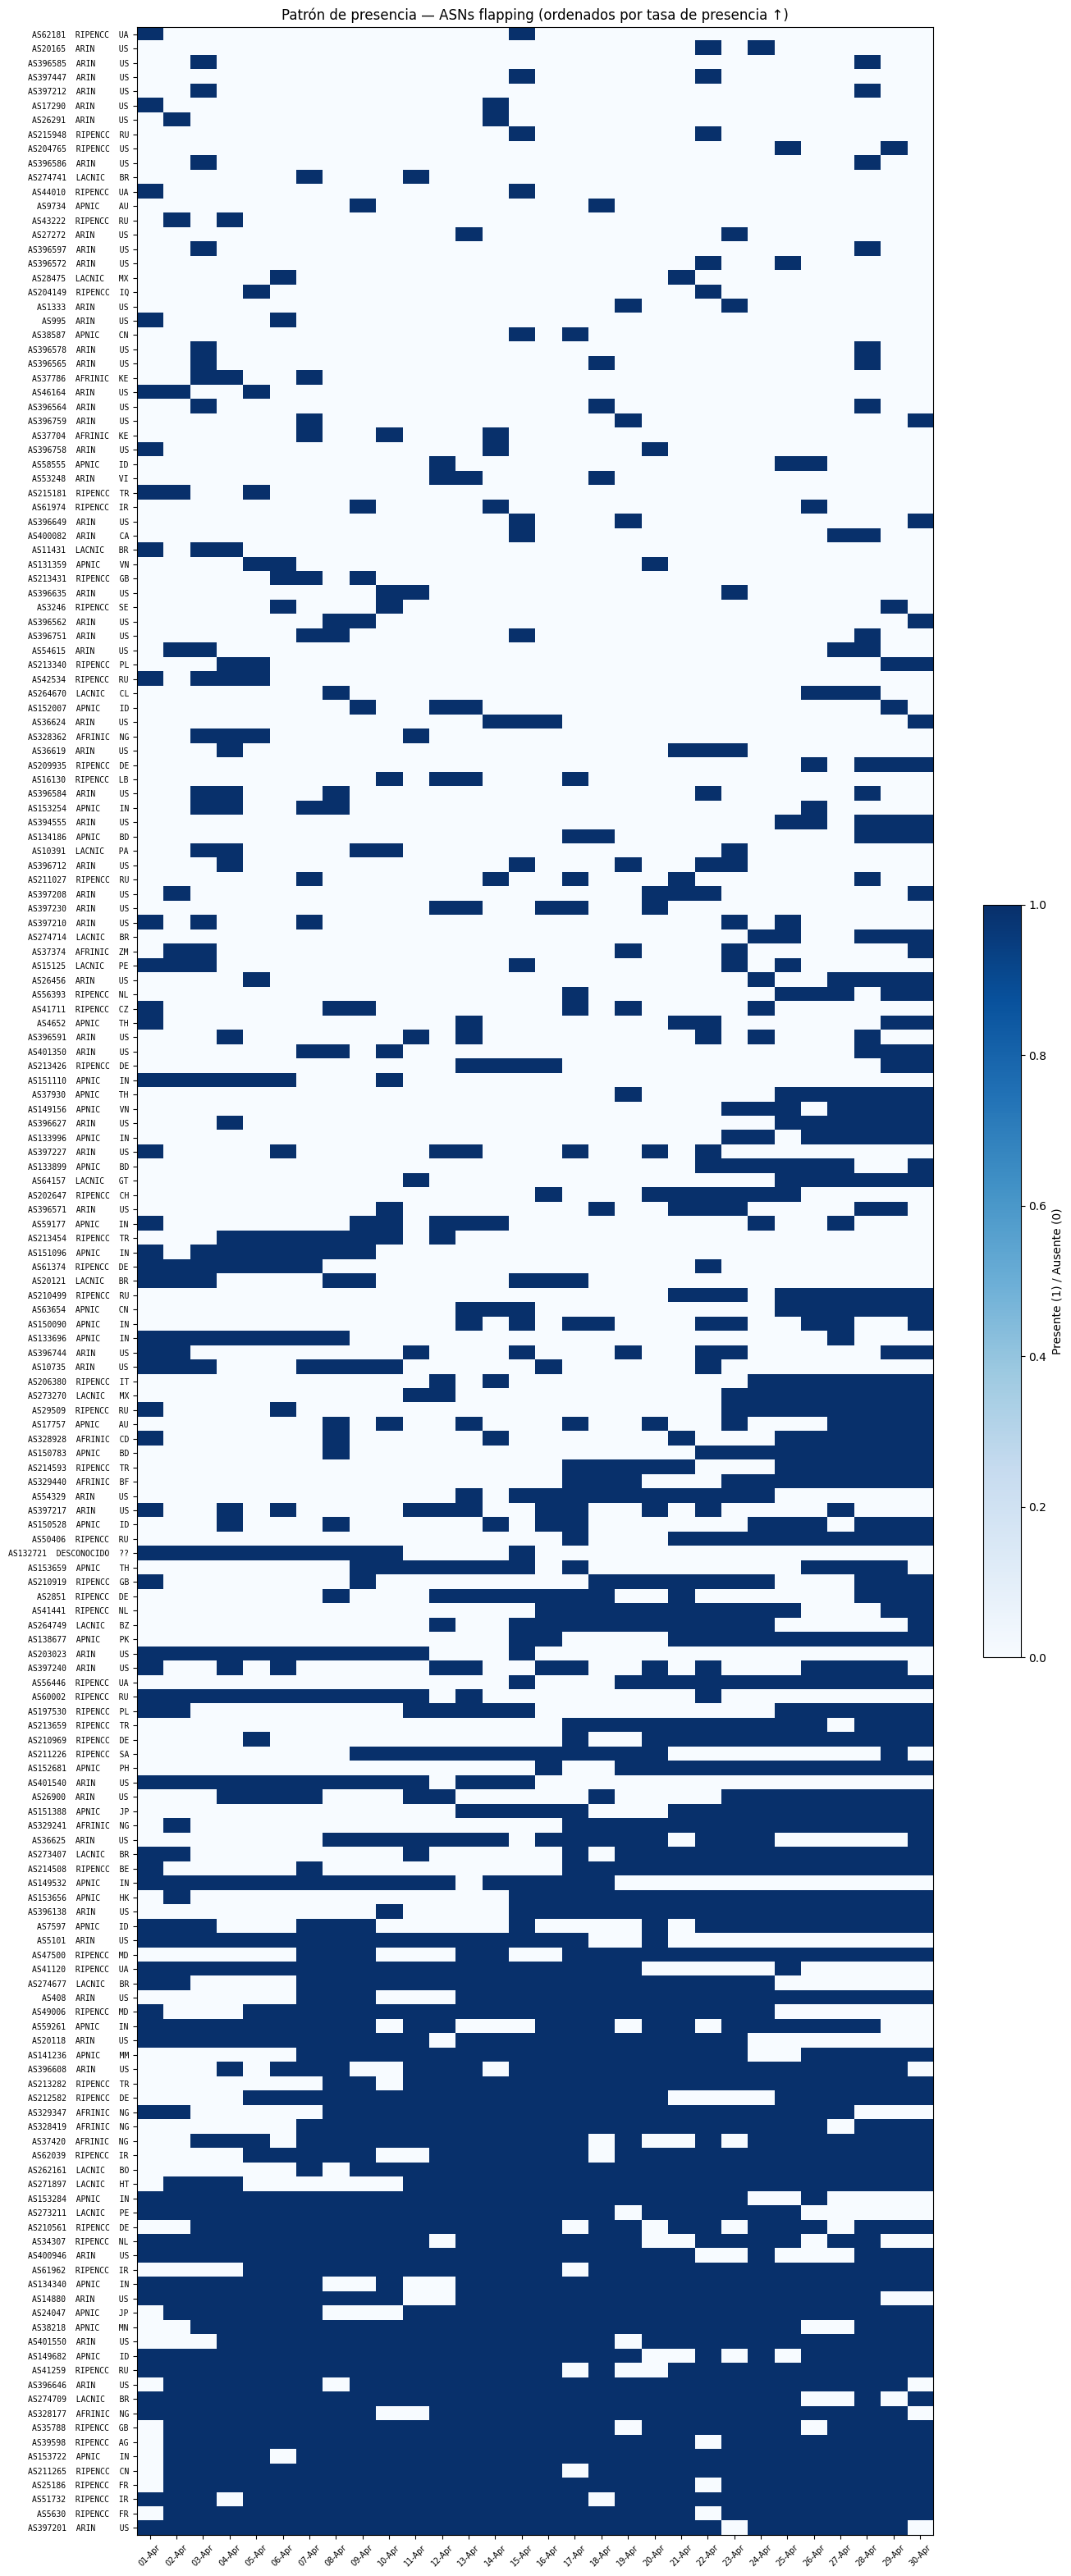

In [17]:
# Plot A — Heatmap de presencia de los 102 flappers (filas ordenadas por tasa)
flap_ord = df_flapping.sort_values("tasa")
mat = df.loc[flap_ord.index].values  # (n_flap, n_dias)

fig_h = max(10, len(flap_ord) * 0.18)
fig, ax = plt.subplots(figsize=(14, fig_h))
im = ax.imshow(mat, aspect="auto", cmap="Blues", interpolation="nearest", vmin=0, vmax=1)

ax.set_xticks(range(n_dias))
ax.set_xticklabels([d.strftime("%d-%b") for d in df.columns], rotation=45, fontsize=7)
ax.set_yticks(range(len(flap_ord)))
ax.set_yticklabels(
    [f"AS{asn}  {row['rir'].upper():7s}  {row['cc'].upper()}" for asn, row in flap_ord.iterrows()],
    fontsize=7, family="monospace"
)
ax.set_title("Patrón de presencia — ASNs flapping (ordenados por tasa de presencia ↑)")
plt.colorbar(im, ax=ax, shrink=0.3, label="Presente (1) / Ausente (0)")
plt.tight_layout()
plt.show()

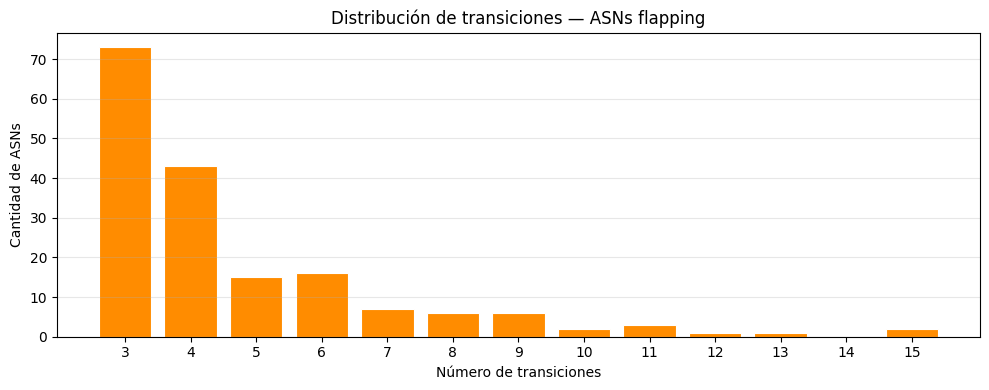

Transiciones: min=3  max=15  media=4.7

Top 15 ASNs más inestables:


,transiciones,tasa,rir,cc
ASN,,,,
397240,15,0.433333,arin,us
397217,15,0.366667,arin,us
17757,13,0.333333,apnic,au
396591,12,0.200000,arin,us
150090,11,0.300000,apnic,in
150528,11,0.366667,apnic,id
397227,11,0.233333,arin,us
211027,10,0.166667,ripencc,ru
396744,10,0.300000,arin,us


In [28]:
# Plot B — Distribución del número de transiciones + top flappers
t_min = df_flapping["transiciones"].min()
t_max = df_flapping["transiciones"].max()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df_flapping["transiciones"], bins=range(t_min, t_max + 2), align="left",
        color="darkorange", edgecolor="white", linewidth=0.8, rwidth=0.8)
ax.set_xticks(range(t_min, t_max + 1))
ax.set_title("Distribución de transiciones — ASNs flapping")
ax.set_xlabel("Número de transiciones")
ax.set_ylabel("Cantidad de ASNs")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Transiciones: min={t_min}  max={t_max}  media={df_flapping['transiciones'].mean():.1f}")
print(f"\nTop 15 ASNs más inestables:")
display(df_flapping.sort_values("transiciones", ascending=False)
        [["transiciones", "tasa", "rir", "cc"]].head(15))

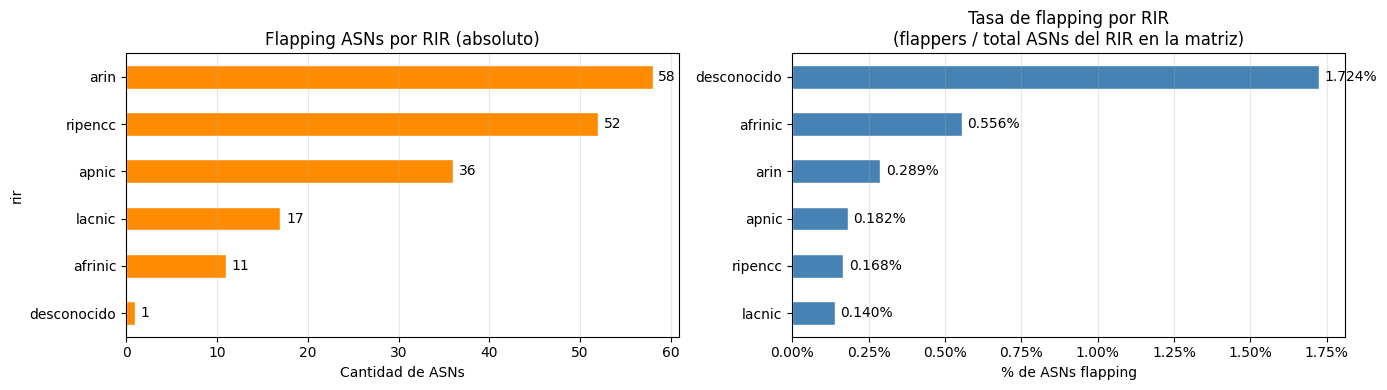


Resumen:


,total,flappers,tasa_%
desconocido,58,1,1.724138
afrinic,1979,11,0.555836
arin,20090,58,0.288701
apnic,19746,36,0.182315
ripencc,31016,52,0.167655
lacnic,12186,17,0.139504


In [19]:
# Plot C — Distribución regional: absoluta y normalizada por población de cada RIR
todos_rirs = pd.Series([asn_to_rir.get(a, "desconocido") for a in df.index])
total_por_rir = todos_rirs.value_counts()
flap_por_rir  = df_flapping["rir"].value_counts()

rirs_comunes = flap_por_rir.index.intersection(total_por_rir.index)
tasa_flap = (flap_por_rir[rirs_comunes] / total_por_rir[rirs_comunes] * 100).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Izquierda: conteo absoluto
flap_por_rir.sort_values().plot.barh(ax=axes[0], color="darkorange", edgecolor="white")
axes[0].bar_label(axes[0].containers[0], padding=4)
axes[0].set_title("Flapping ASNs por RIR (absoluto)")
axes[0].set_xlabel("Cantidad de ASNs")
axes[0].grid(axis="x", alpha=0.3)

# Derecha: tasa normalizada (flappers / total ASNs del RIR)
tasa_flap.plot.barh(ax=axes[1], color="steelblue", edgecolor="white")
axes[1].bar_label(axes[1].containers[0], fmt="%.3f%%", padding=4)
axes[1].set_title("Tasa de flapping por RIR\n(flappers / total ASNs del RIR en la matriz)")
axes[1].set_xlabel("% de ASNs flapping")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.2f}%"))
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nResumen:")
resumen = pd.DataFrame({
    "total":     total_por_rir[rirs_comunes],
    "flappers":  flap_por_rir[rirs_comunes],
    "tasa_%":    tasa_flap,
}).sort_values("tasa_%", ascending=False)
display(resumen)

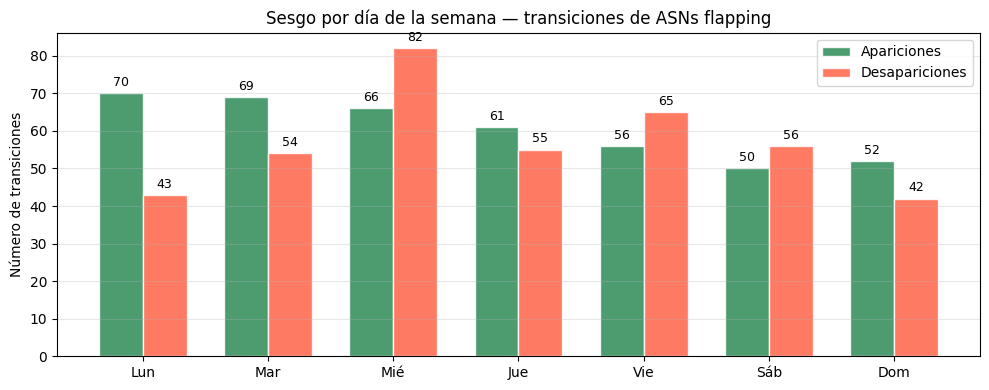

In [20]:
# Plot D — Sesgo por día de la semana en las transiciones de flappers
diff_flap = df.loc[flap_asns].diff(axis=1).iloc[:, 1:]

ap_por_dia  = (diff_flap ==  1).sum(axis=0)
des_por_dia = (diff_flap == -1).sum(axis=0)

dow_ap  = ap_por_dia.groupby(ap_por_dia.index.dayofweek).sum()
dow_des = des_por_dia.groupby(des_por_dia.index.dayofweek).sum()

nombres_dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
x     = np.arange(7)
width = 0.35

fig, ax = plt.subplots(figsize=(10, 4))
b_ap  = ax.bar(x - width/2, [dow_ap.get(i, 0)  for i in range(7)],
               width, label="Apariciones",    color="seagreen", alpha=0.85, edgecolor="white")
b_des = ax.bar(x + width/2, [dow_des.get(i, 0) for i in range(7)],
               width, label="Desapariciones", color="tomato",   alpha=0.85, edgecolor="white")
ax.bar_label(b_ap,  padding=3, fontsize=9)
ax.bar_label(b_des, padding=3, fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(nombres_dias)
ax.set_title("Sesgo por día de la semana — transiciones de ASNs flapping")
ax.set_ylabel("Número de transiciones")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 9. ¿Los flappers vuelven con los mismos peers?

Para cada ASN flapping, segmentamos su presencia en **episodios** (rachas contiguas de días presentes). El conjunto de peers de cada episodio se define como la **intersección** de los vecinos observados en todos los días de ese episodio — sólo los peers estables dentro del episodio cuentan. Luego comparamos episodios consecutivos: ¿los peers cambian entre una desaparición y la siguiente reaparición? ¿Cambia la composición geográfica?

In [21]:
# Leer archivos de topología diarios y construir dict: ASN → {fecha → frozenset(peers)}
# Sólo se leen las aristas donde un extremo es un flapper — el resto se descarta.
import re
from pathlib import Path

flap_set   = set(int(a) for a in flap_asns)
date_by_str = {d.strftime("%Y%m%d"): d for d in df.columns}

peers_per_day: dict[int, dict] = {a: {} for a in flap_set}

topo_files = sorted(Path(TOPOLOGY_DIR).glob("topology-????????.txt"))
print(f"Archivos de topología encontrados: {len(topo_files)}")

for path in topo_files:
    m = re.search(r"topology-(\d{8})\.txt$", path.name)
    if not m or m.group(1) not in date_by_str:
        continue
    date = date_by_str[m.group(1)]
    tmp: dict[int, set] = {a: set() for a in flap_set}
    with open(path) as fh:
        for line in fh:
            s = line.split()
            if len(s) < 2:
                continue
            a1, a2 = int(s[0]), int(s[1])
            if a1 in flap_set:
                tmp[a1].add(a2)
            if a2 in flap_set:
                tmp[a2].add(a1)
    for asn in flap_set:
        if tmp[asn]:
            peers_per_day[asn][date] = frozenset(tmp[asn])

covered = sum(1 for a in flap_set if peers_per_day[a])
print(f"Flappers con al menos 1 día de peers leído: {covered} / {len(flap_set)}")

Archivos de topología encontrados: 30
Flappers con al menos 1 día de peers leído: 175 / 175


In [22]:
# Segmentar en episodios y calcular Jaccard entre episodios consecutivos
def episodios(asn_int):
    row  = df.loc[asn_int].values.astype(int)
    cols = df.columns
    result = []
    i = 0
    while i < len(row):
        if row[i] == 1:
            j = i
            while j < len(row) and row[j] == 1:
                j += 1
            ep_dates = list(cols[i:j])
            daily    = [peers_per_day[asn_int].get(d, frozenset()) for d in ep_dates]
            non_empty = [s for s in daily if s]
            peer_ix  = frozenset.intersection(*non_empty) if non_empty else frozenset()
            result.append({"dates": ep_dates, "peers": peer_ix, "n_days": j - i})
            i = j
        else:
            i += 1
    return result

records = []
for asn_int in sorted(flap_set):
    eps = episodios(asn_int)
    for k in range(len(eps) - 1):
        pb, pa = eps[k]["peers"], eps[k + 1]["peers"]
        union   = pb | pa
        jaccard = len(pb & pa) / len(union) if union else float("nan")
        absent_days = (eps[k + 1]["dates"][0] - eps[k]["dates"][-1]).days - 1
        records.append({
            "asn":            asn_int,
            "rir":            asn_to_rir.get(asn_int, "desconocido"),
            "cc":             asn_to_cc.get(asn_int, "??"),
            "ep_idx":         k,
            "n_days_before":  eps[k]["n_days"],
            "n_days_absent":  absent_days,
            "n_days_after":   eps[k + 1]["n_days"],
            "peers_before":   len(pb),
            "peers_after":    len(pa),
            "gained":         len(pa - pb),
            "lost":           len(pb - pa),
            "jaccard":        jaccard,
            "_pb":            pb,
            "_pa":            pa,
        })

df_trans = pd.DataFrame(records)
print(f"Transiciones de episodio: {len(df_trans)}  (flappers con ≥2 episodios: {df_trans['asn'].nunique()})")
print(df_trans[["asn", "rir", "ep_idx", "peers_before", "peers_after",
                "gained", "lost", "jaccard"]].head(10).to_string(index=False))

Transiciones de episodio: 304  (flappers con ≥2 episodios: 175)
 asn     rir  ep_idx  peers_before  peers_after  gained  lost  jaccard
 408    arin       0             1            1       0     0      1.0
 995    arin       0             1            1       0     0      1.0
1333    arin       0             2            2       0     0      1.0
2851 ripencc       0             2            1       0     1      0.5
2851 ripencc       1             1            2       1     0      0.5
2851 ripencc       2             2            1       0     1      0.5
3246 ripencc       0             1            1       0     0      1.0
3246 ripencc       1             1            2       1     0      0.5
4652   apnic       0             2            2       2     2      0.0
4652   apnic       1             2            2       2     2      0.0


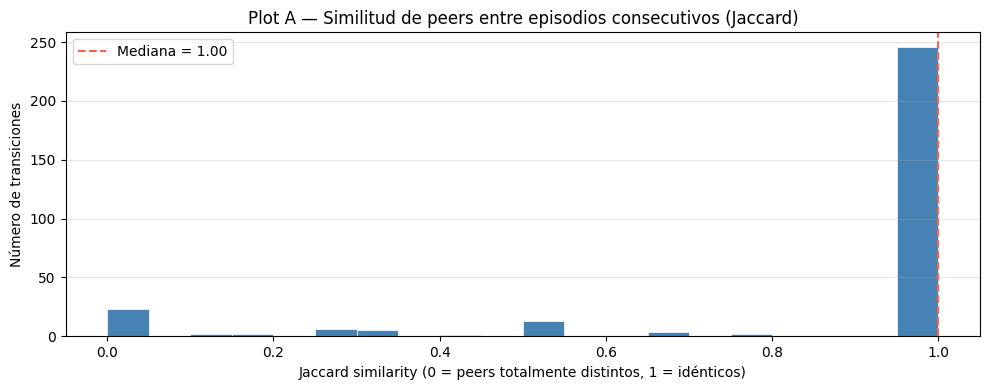

Total de transiciones: 304  |  con peers vacíos (NaN): 0

Rango Jaccard   Transiciones
──────────────────────────────
0–0.1             23  █
0.1–0.3           10  
0.3–0.5            6  
0.5–0.7           17  █
0.7–0.9            2  
0.9–1.0          246  ████████████████████


In [23]:
# Plot A — Distribución de similitud de Jaccard entre episodios consecutivos
fig, ax = plt.subplots(figsize=(10, 4))

valid = df_trans["jaccard"].dropna()
median_j = valid.median()
ax.hist(valid, bins=20, color="steelblue", edgecolor="white", linewidth=0.5, range=(0, 1))
ax.axvline(median_j, color="tomato", linestyle="--", linewidth=1.5,
           label=f"Mediana = {median_j:.2f}")
ax.set_title("Plot A — Similitud de peers entre episodios consecutivos (Jaccard)")
ax.set_xlabel("Jaccard similarity (0 = peers totalmente distintos, 1 = idénticos)")
ax.set_ylabel("Número de transiciones")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Breakdown table
bins   = [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.01]
labels = ["0–0.1", "0.1–0.3", "0.3–0.5", "0.5–0.7", "0.7–0.9", "0.9–1.0"]
counts = pd.cut(valid, bins=bins, labels=labels, right=False).value_counts().sort_index()
print(f"Total de transiciones: {len(valid)}  |  con peers vacíos (NaN): {df_trans['jaccard'].isna().sum()}")
print(f"\nRango Jaccard   Transiciones")
print("─" * 30)
for lbl, cnt in counts.items():
    bar = "█" * int(cnt / max(counts) * 20)
    print(f"{lbl:<14}  {cnt:>4}  {bar}")

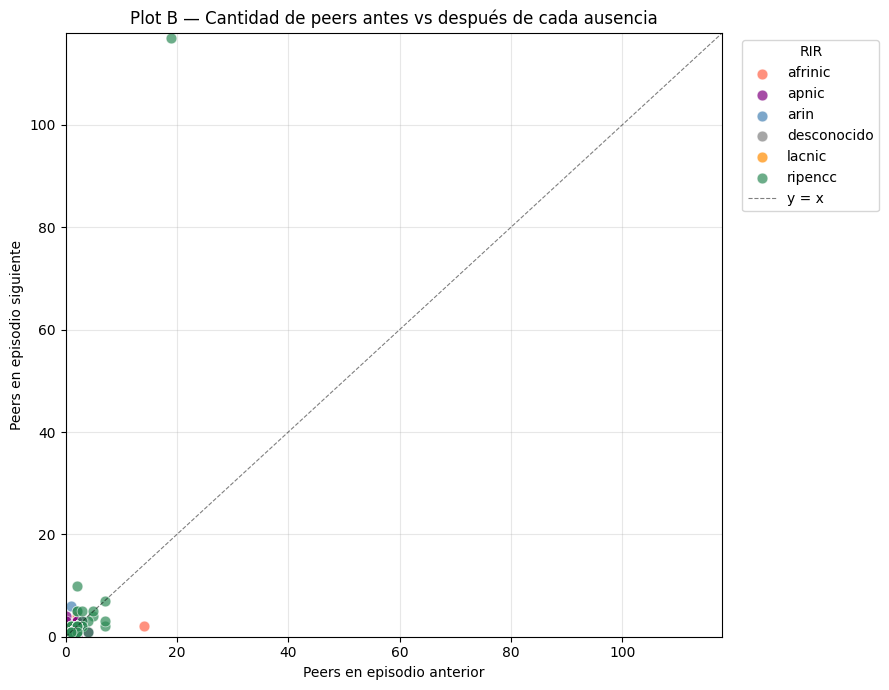

Transiciones con más peers después:  20
Transiciones con menos peers después: 23
Sin cambio en número de peers:        261

Mediana ganados: 0   perdidos: 0


In [24]:
# Plot B — Peers antes vs después de cada ausencia (scatter, coloreado por RIR)
import pandas as pd

rir_colors = {
    "arin":        "steelblue",
    "ripencc":     "seagreen",
    "lacnic":      "darkorange",
    "apnic":       "purple",
    "afrinic":     "tomato",
    "desconocido": "gray",
}

fig, ax = plt.subplots(figsize=(9, 7))

for rir, grp in df_trans.groupby("rir"):
    ax.scatter(
        grp["peers_before"], grp["peers_after"],
        label=rir, color=rir_colors.get(rir, "gray"),
        alpha=0.7, s=60, edgecolors="white", linewidths=0.5,
    )

# Identity line
lim = max(df_trans["peers_before"].max(), df_trans["peers_after"].max()) + 1
ax.plot([0, lim], [0, lim], "k--", linewidth=0.8, alpha=0.5, label="y = x")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("Peers en episodio anterior")
ax.set_ylabel("Peers en episodio siguiente")
ax.set_title("Plot B — Cantidad de peers antes vs después de cada ausencia")
ax.legend(title="RIR", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Summary stats
print(f"Transiciones con más peers después:  {(df_trans['peers_after'] > df_trans['peers_before']).sum()}")
print(f"Transiciones con menos peers después: {(df_trans['peers_after'] < df_trans['peers_before']).sum()}")
print(f"Sin cambio en número de peers:        {(df_trans['peers_after'] == df_trans['peers_before']).sum()}")
print(f"\nMediana ganados: {df_trans['gained'].median():.0f}   perdidos: {df_trans['lost'].median():.0f}")

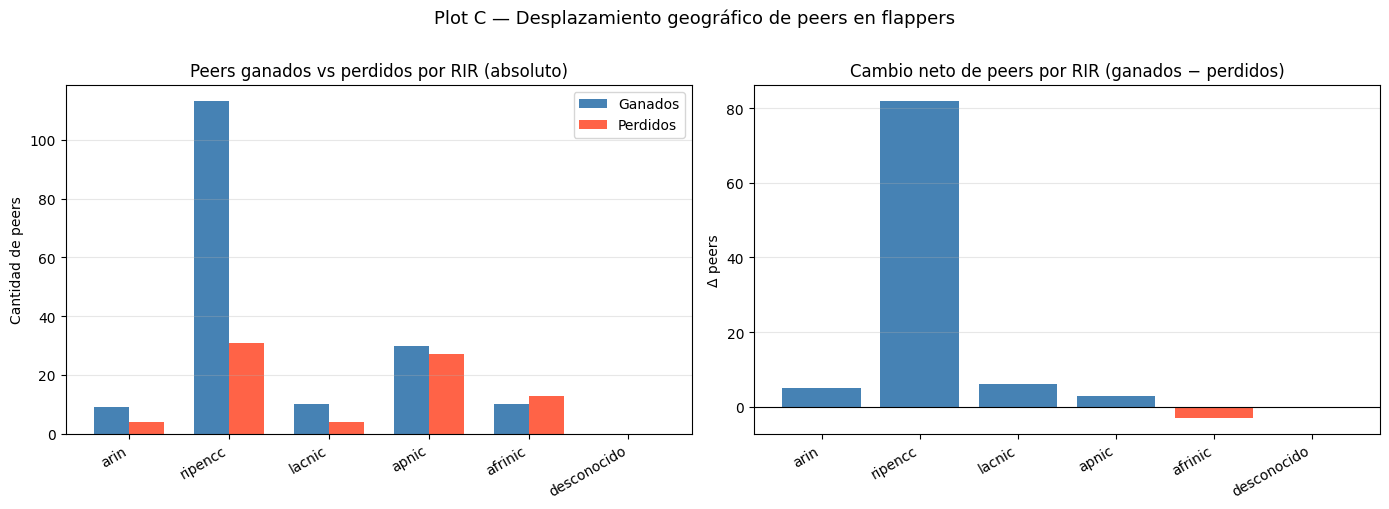


RIR            Ganados  Perdidos   Neto
────────────────────────────────────────────
arin                  9        4       +5
ripencc             113       31      +82
lacnic               10        4       +6
apnic                30       27       +3
afrinic              10       13       -3
desconocido           0        0       +0


In [25]:
# Plot C — Composición geográfica de peers: ganados vs perdidos por RIR
from collections import defaultdict

gained_by_rir = defaultdict(int)
lost_by_rir   = defaultdict(int)

for rec in records:
    for p in rec["_pa"] - rec["_pb"]:
        gained_by_rir[asn_to_rir.get(p, "desconocido")] += 1
    for p in rec["_pb"] - rec["_pa"]:
        lost_by_rir[asn_to_rir.get(p, "desconocido")] += 1

rir_order = ["arin", "ripencc", "lacnic", "apnic", "afrinic", "desconocido"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(rir_order))
w = 0.35
ax = axes[0]
ax.bar(x - w/2, [gained_by_rir[r] for r in rir_order], w, label="Ganados", color="steelblue")
ax.bar(x + w/2, [lost_by_rir[r]   for r in rir_order], w, label="Perdidos", color="tomato")
ax.set_xticks(x); ax.set_xticklabels(rir_order, rotation=30, ha="right")
ax.set_title("Peers ganados vs perdidos por RIR (absoluto)")
ax.set_ylabel("Cantidad de peers")
ax.legend()
ax.grid(axis="y", alpha=0.3)

net = [gained_by_rir[r] - lost_by_rir[r] for r in rir_order]
colors_net = ["steelblue" if v >= 0 else "tomato" for v in net]
ax2 = axes[1]
ax2.bar(x, net, color=colors_net)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_xticks(x); ax2.set_xticklabels(rir_order, rotation=30, ha="right")
ax2.set_title("Cambio neto de peers por RIR (ganados − perdidos)")
ax2.set_ylabel("Δ peers")
ax2.grid(axis="y", alpha=0.3)

plt.suptitle("Plot C — Desplazamiento geográfico de peers en flappers", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print("\nRIR            Ganados  Perdidos   Neto")
print("─" * 44)
for r in rir_order:
    g, l = gained_by_rir[r], lost_by_rir[r]
    print(f"{r:<16} {g:>6,}   {l:>6,}   {g - l:>+6,}")

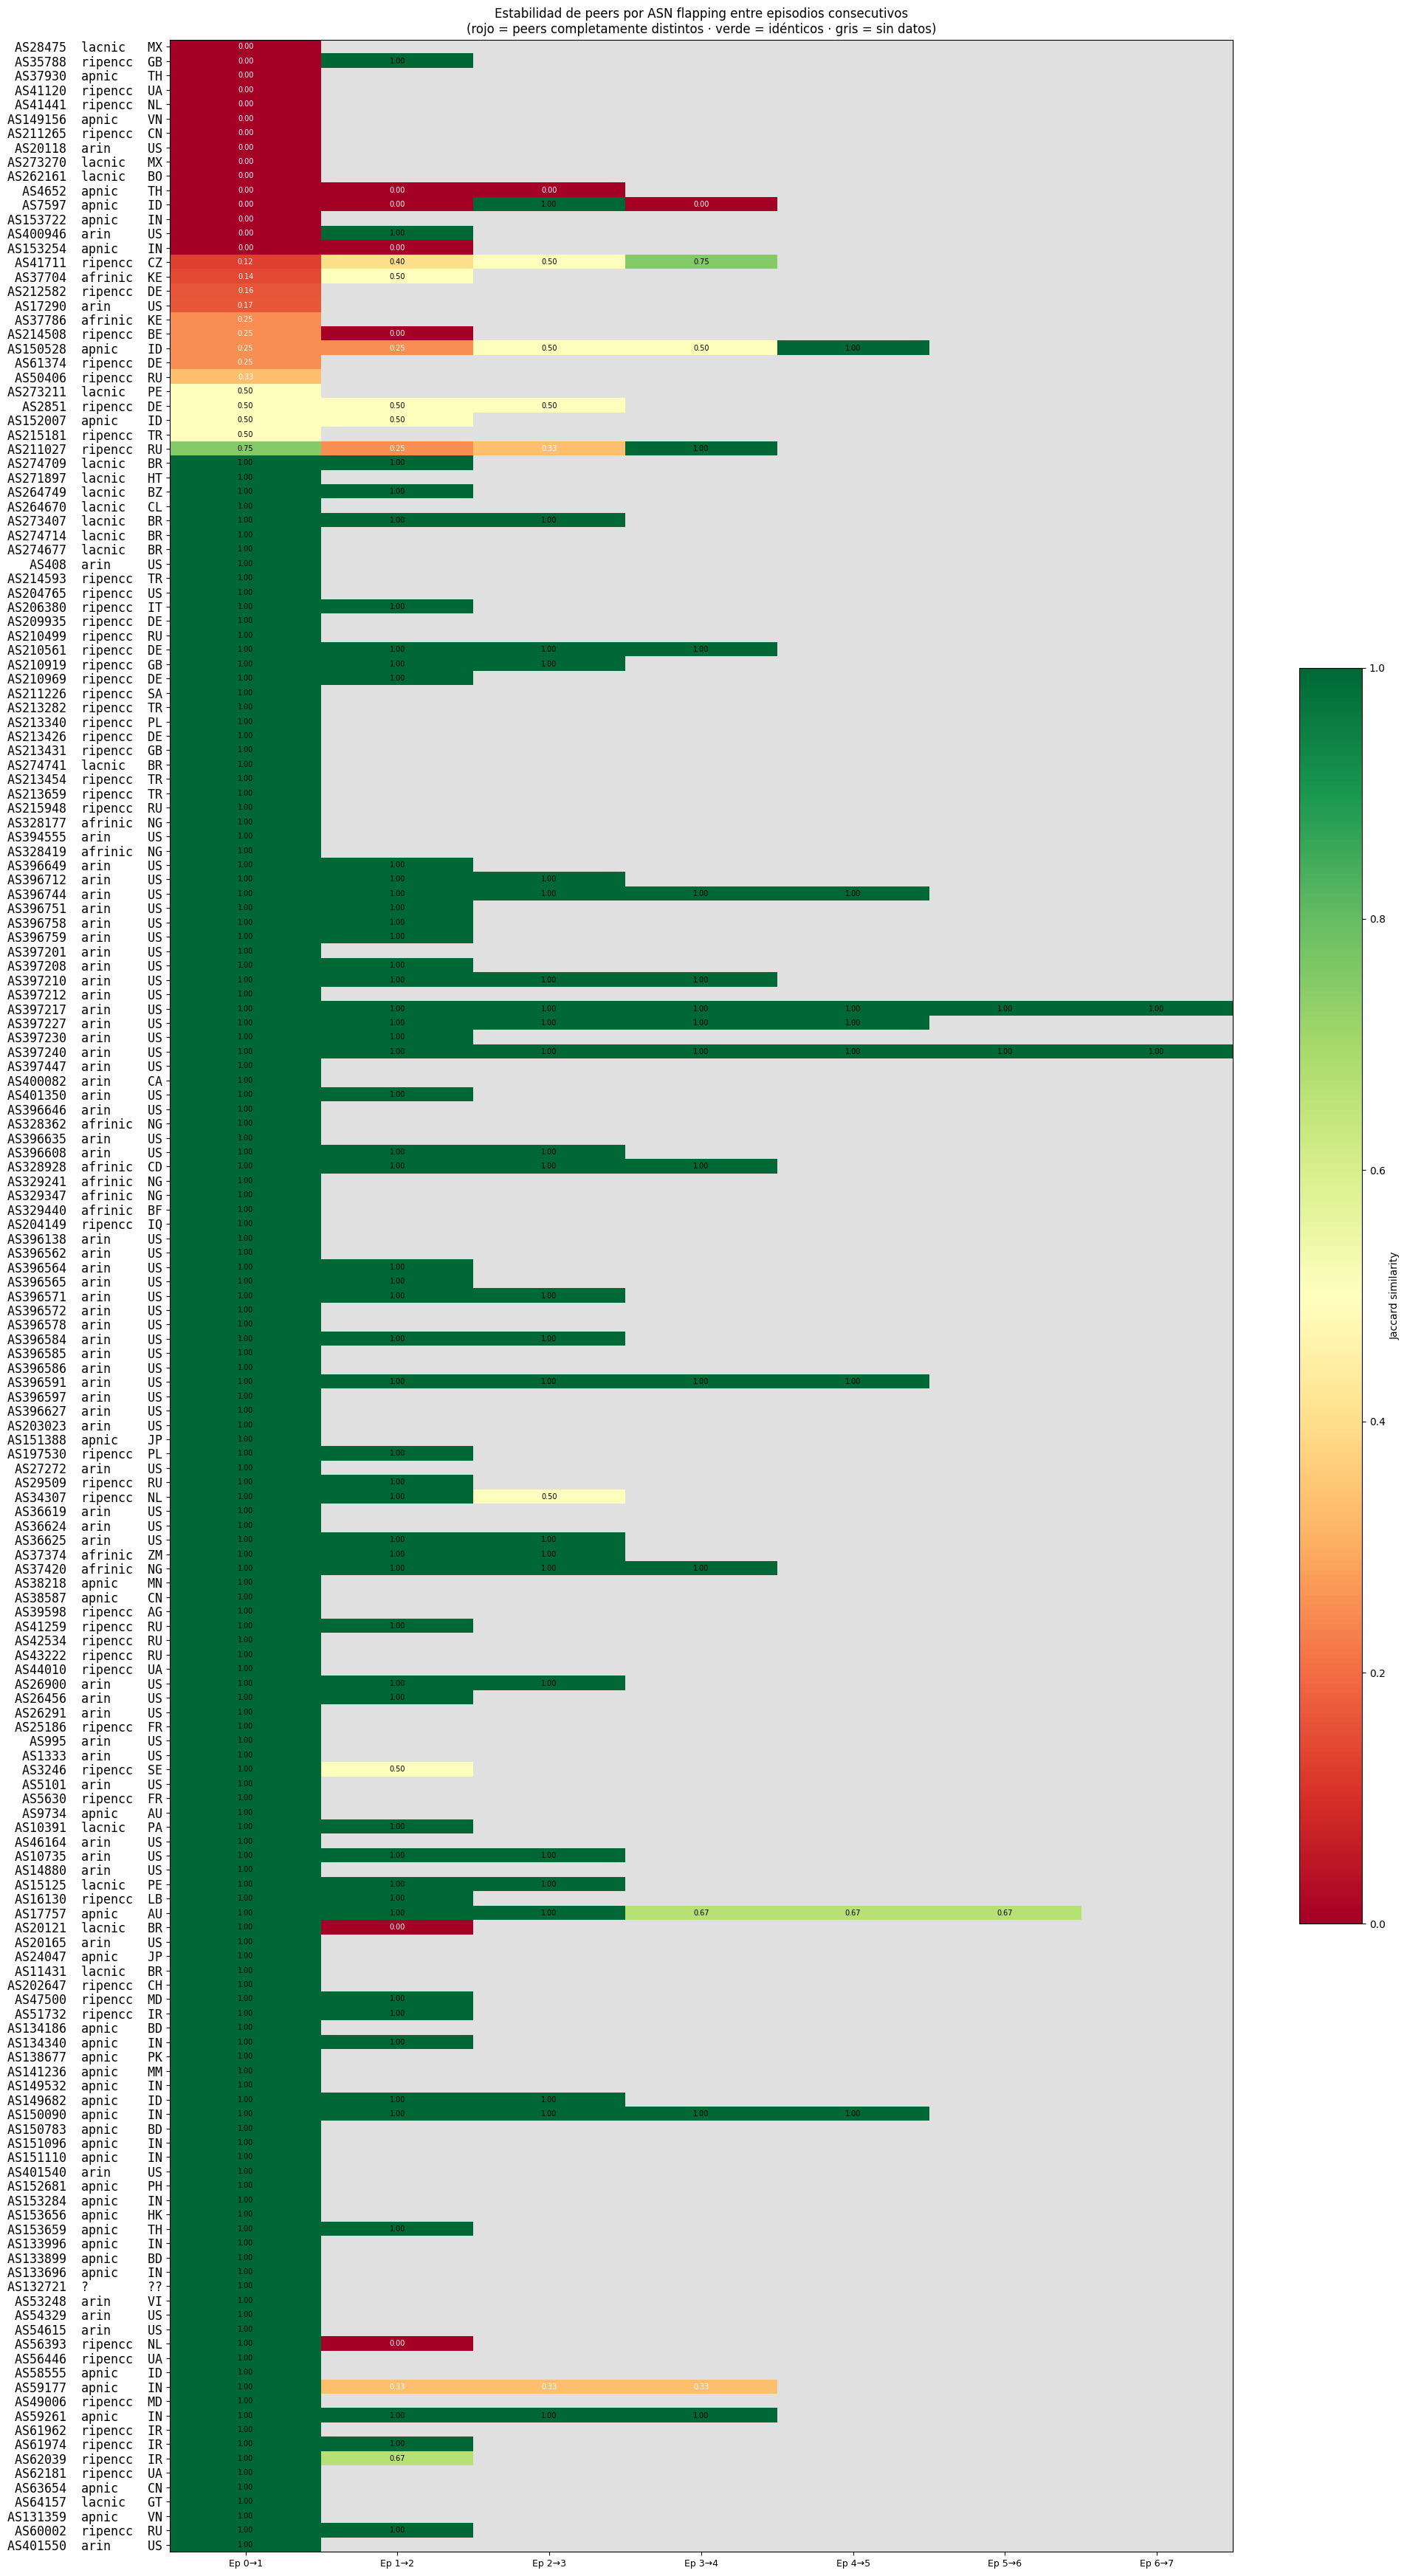

In [30]:
# Plot D — Heatmap de Jaccard por flapper y transición de episodio
asns_ord  = sorted(df_trans["asn"].unique())
max_trans = int(df_trans["ep_idx"].max()) + 1

jac_mat = pd.DataFrame(np.nan, index=asns_ord, columns=range(max_trans))
for _, row in df_trans.iterrows():
    jac_mat.loc[row["asn"], row["ep_idx"]] = row["jaccard"]

jac_mat = jac_mat.sort_values(0)  # más volátiles arriba

cmap_rg = plt.cm.RdYlGn.copy()
cmap_rg.set_bad(color="#e0e0e0")
data = np.ma.masked_invalid(jac_mat.values.astype(float))

fig_h = max(8, len(jac_mat) * 0.2)
fig, ax = plt.subplots(figsize=(max(7, max_trans * 2.5 + 3), fig_h))
im = ax.imshow(data, aspect="auto", cmap=cmap_rg, vmin=0, vmax=1, interpolation="nearest")

ax.set_xticks(range(max_trans))
ax.set_xticklabels([f"Ep {i}→{i+1}" for i in range(max_trans)], fontsize=9)
ax.set_yticks(range(len(jac_mat)))
ax.set_yticklabels(
    [f"AS{a}  {asn_to_rir.get(a,'?'):7s}  {asn_to_cc.get(a,'??').upper()}"
     for a in jac_mat.index],
    fontsize=12, family="monospace",
)
for i in range(len(jac_mat)):
    for j in range(max_trans):
        v = jac_mat.iloc[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    fontsize=7, color="white" if v < 0.4 else "black")

plt.colorbar(im, ax=ax, label="Jaccard similarity", shrink=0.5)
ax.set_title("Estabilidad de peers por ASN flapping entre episodios consecutivos\n"
             "(rojo = peers completamente distintos · verde = idénticos · gris = sin datos)")
plt.tight_layout()
plt.show()